In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
import pickle

In [3]:
data=pd.read_csv("customer_churn.csv")

print("Dataset Load successfully !")

Dataset Load successfully !


In [4]:
print("kernel working!")

kernel working!


In [5]:
data.head()

,CustomerID,Gender,Age,Tenure,MonthlyCharges,Contract,InternetService,PaymentMethod,TechSupport,OnlineSecurity,PaperlessBilling,Churn
0,CUST0001,Male,19,35,44.49,Month-to-month,DSL,Electronic check,Yes,No,Yes,Yes
1,CUST0002,Male,50,3,76.12,One year,Fiber optic,Credit card,No,Yes,No,No
2,CUST0003,Male,66,20,89.81,Month-to-month,DSL,Electronic check,No,Yes,No,Yes
3,CUST0004,Female,56,33,100.71,One year,Fiber optic,Bank transfer,No,Yes,No,No
4,CUST0005,Male,20,29,97.31,Two year,No,Electronic check,No,No,No,No


In [6]:
data.tail()

,CustomerID,Gender,Age,Tenure,MonthlyCharges,Contract,InternetService,PaymentMethod,TechSupport,OnlineSecurity,PaperlessBilling,Churn
295,CUST0296,Male,39,61,90.45,Month-to-month,Fiber optic,Electronic check,No,Yes,Yes,Yes
296,CUST0297,Male,44,70,92.20,One year,DSL,Mailed check,No,No,Yes,Yes
297,CUST0298,Female,27,6,56.08,Month-to-month,DSL,Electronic check,No,Yes,Yes,Yes
298,CUST0299,Female,23,60,104.38,Month-to-month,Fiber optic,Electronic check,No,No,No,Yes
299,CUST0300,Female,41,23,64.58,Month-to-month,Fiber optic,Electronic check,Yes,No,Yes,Yes


In [7]:
print("Rows :",data.shape[0])
print("Columns :",data.shape[1])

Rows : 300
Columns : 12


In [8]:
print(data.columns)

Index(['CustomerID', 'Gender', 'Age', 'Tenure', 'MonthlyCharges', 'Contract',
       'InternetService', 'PaymentMethod', 'TechSupport', 'OnlineSecurity',
       'PaperlessBilling', 'Churn'],
      dtype='str')


In [9]:
# Dataset information
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 300 entries, 0 to 299
Data columns (total 12 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   CustomerID        300 non-null    str    
 1   Gender            300 non-null    str    
 2   Age               300 non-null    int64  
 3   Tenure            300 non-null    int64  
 4   MonthlyCharges    300 non-null    float64
 5   Contract          300 non-null    str    
 6   InternetService   300 non-null    str    
 7   PaymentMethod     300 non-null    str    
 8   TechSupport       300 non-null    str    
 9   OnlineSecurity    300 non-null    str    
 10  PaperlessBilling  300 non-null    str    
 11  Churn             300 non-null    str    
dtypes: float64(1), int64(2), str(9)
memory usage: 44.3 KB


In [10]:
data.describe()

,Age,Tenure,MonthlyCharges
count,300.000000,300.000000,300.000000
mean,46.773333,36.513333,70.407533
std,16.571381,22.040624,28.865693
min,18.000000,0.000000,21.580000
25%,33.750000,17.000000,44.997500
50%,46.000000,36.500000,69.660000
75%,61.250000,57.000000,96.802500
max,75.000000,72.000000,119.060000


In [11]:
# Missing Values
data.isnull().sum()

CustomerID          0
Gender              0
Age                 0
Tenure              0
MonthlyCharges      0
Contract            0
InternetService     0
PaymentMethod       0
TechSupport         0
OnlineSecurity      0
PaperlessBilling    0
Churn               0
dtype: int64

In [12]:
# Duplicate Check
print("Duplicate rows :",data.duplicated().sum())

Duplicate rows : 0


In [13]:
# Categorical_columns
categorical_columns = data.select_dtypes(
    include="object"
).columns

print(categorical_columns)

Index(['CustomerID', 'Gender', 'Contract', 'InternetService', 'PaymentMethod',
       'TechSupport', 'OnlineSecurity', 'PaperlessBilling', 'Churn'],
      dtype='str')


C:\Users\HP\AppData\Local\Temp\ipykernel_24528\26635325.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = data.select_dtypes(


In [14]:
# Numerical_columns
numerical_columns=data.select_dtypes(
    include=np.number
).columns

print(numerical_columns)

Index(['Age', 'Tenure', 'MonthlyCharges'], dtype='str')


In [15]:
# Churn Distribution
print(data["Churn"].value_counts())

Churn
No     164
Yes    136
Name: count, dtype: int64


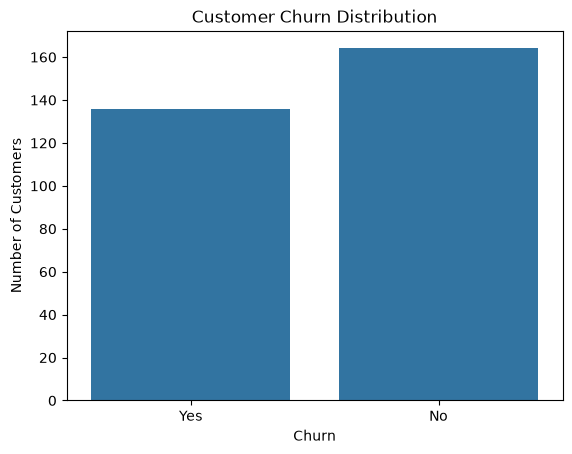

In [16]:
sns.countplot(x="Churn", data=data)

plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")

plt.show()

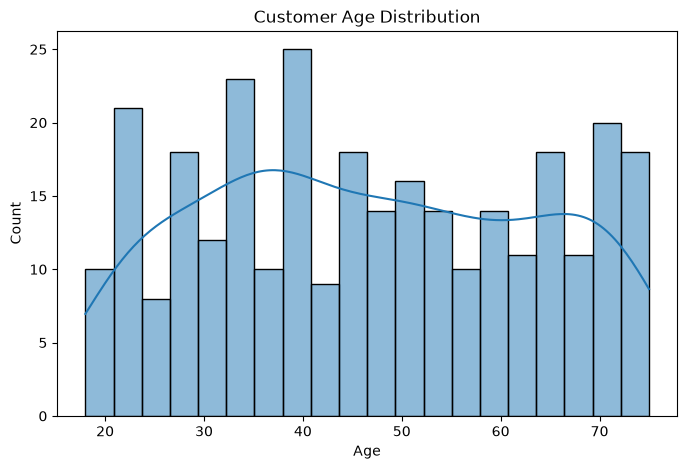

In [17]:
plt.figure(figsize=(8,5))

sns.histplot(
    data["Age"],
    bins=20,
    kde=True
)

plt.title("Customer Age Distribution")
plt.xlabel("Age")
plt.ylabel("Count")

plt.show()

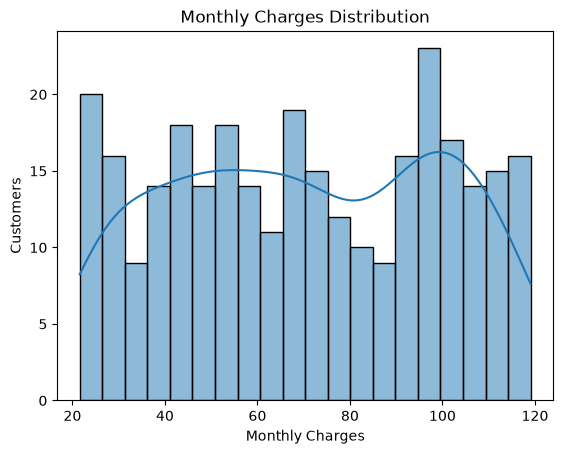

In [18]:
plt.Figure(figsize=(8,5))

sns.histplot(
    data["MonthlyCharges"],
    bins=20,
    kde=True
)

plt.title("Monthly Charges Distribution")
plt.xlabel("Monthly Charges")
plt.ylabel("Customers")
plt.show()

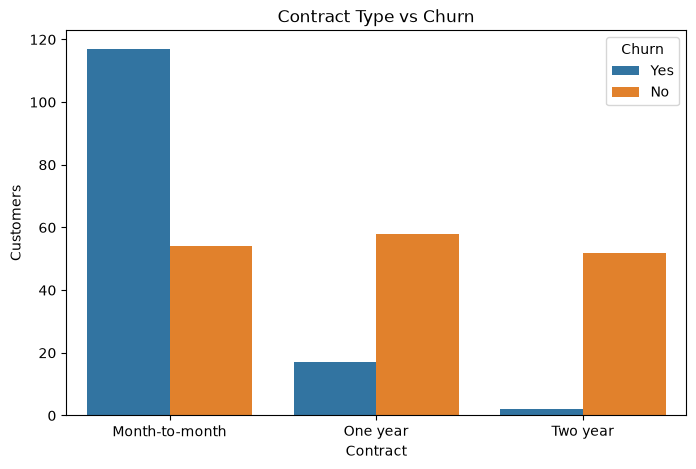

In [19]:
plt.figure(figsize=(8,5))

sns.countplot(
    x="Contract",
    hue="Churn",
    data=data
)

plt.title("Contract Type vs Churn")
plt.xlabel("Contract")
plt.ylabel("Customers")

plt.show()

In [20]:
data.count()

CustomerID          300
Gender              300
Age                 300
Tenure              300
MonthlyCharges      300
Contract            300
InternetService     300
PaymentMethod       300
TechSupport         300
OnlineSecurity      300
PaperlessBilling    300
Churn               300
dtype: int64

In [21]:
print(
    "Duplicate Customer IDs:",
    data["CustomerID"].duplicated().sum()
)

Duplicate Customer IDs: 0


In [22]:
print(data.dtypes)

CustomerID              str
Gender                  str
Age                   int64
Tenure                int64
MonthlyCharges      float64
Contract                str
InternetService         str
PaymentMethod           str
TechSupport             str
OnlineSecurity          str
PaperlessBilling        str
Churn                   str
dtype: object


In [23]:
print(data["Gender"].unique())

<ArrowStringArray>
['Male', 'Female']
Length: 2, dtype: str


In [24]:
print(data["Contract"].value_counts())

Contract
Month-to-month    171
One year           75
Two year           54
Name: count, dtype: int64


In [25]:
# Numerical columns check
numerical_columns = [
    "Age",
    "Tenure",
    "MonthlyCharges"
]
data[numerical_columns].describe()

,Age,Tenure,MonthlyCharges
count,300.000000,300.000000,300.000000
mean,46.773333,36.513333,70.407533
std,16.571381,22.040624,28.865693
min,18.000000,0.000000,21.580000
25%,33.750000,17.000000,44.997500
50%,46.000000,36.500000,69.660000
75%,61.250000,57.000000,96.802500
max,75.000000,72.000000,119.060000


In [26]:
# Logical Range Check
print(data["Age"].min())
print(data["Age"].max())

18
75


In [27]:
print(data["Tenure"].min())
print(data["Tenure"].max())

0
72


In [28]:
# Churn Target Check
print(data["Churn"].value_counts())


Churn
No     164
Yes    136
Name: count, dtype: int64


In [29]:
# Copy clean data
clean_data=data.copy()

In [30]:
clean_data.to_csv(
    "customer_churn_clean.csv",
    index=False
)

print("Clean dataset saved successfully!")

Clean dataset saved successfully!


In [31]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

data = pd.read_csv("customer_churn_clean.csv")

print(data.shape)
data.head()

(300, 12)


,CustomerID,Gender,Age,Tenure,MonthlyCharges,Contract,InternetService,PaymentMethod,TechSupport,OnlineSecurity,PaperlessBilling,Churn
0,CUST0001,Male,19,35,44.49,Month-to-month,DSL,Electronic check,Yes,No,Yes,Yes
1,CUST0002,Male,50,3,76.12,One year,Fiber optic,Credit card,No,Yes,No,No
2,CUST0003,Male,66,20,89.81,Month-to-month,DSL,Electronic check,No,Yes,No,Yes
3,CUST0004,Female,56,33,100.71,One year,Fiber optic,Bank transfer,No,Yes,No,No
4,CUST0005,Male,20,29,97.31,Two year,No,Electronic check,No,No,No,No


In [34]:
# Churn distribution
print(data["Churn"].value_counts())

Churn
No     164
Yes    136
Name: count, dtype: int64


Text(0, 0.5, 'Number of Customers')

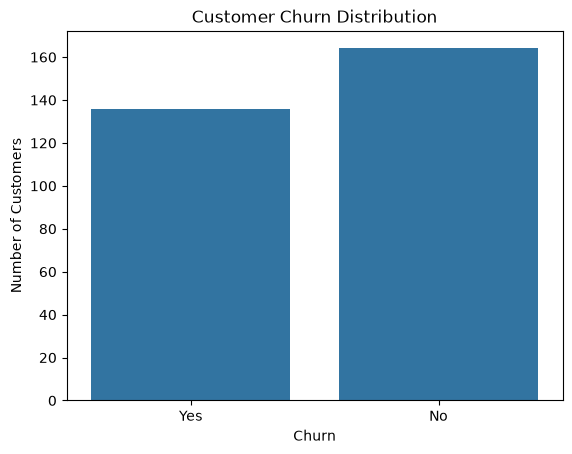

In [33]:
plt.Figure(figsize=(7,5))

sns.countplot(
    x="Churn",
    data=data
)
plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")

In [41]:
contract_churn = pd.crosstab(
    data["Contract"],
    data["Churn"],
    normalize="index"
) * 100

print(contract_churn)

Churn                  No        Yes
Contract                            
Month-to-month  31.578947  68.421053
One year        77.333333  22.666667
Two year        96.296296   3.703704


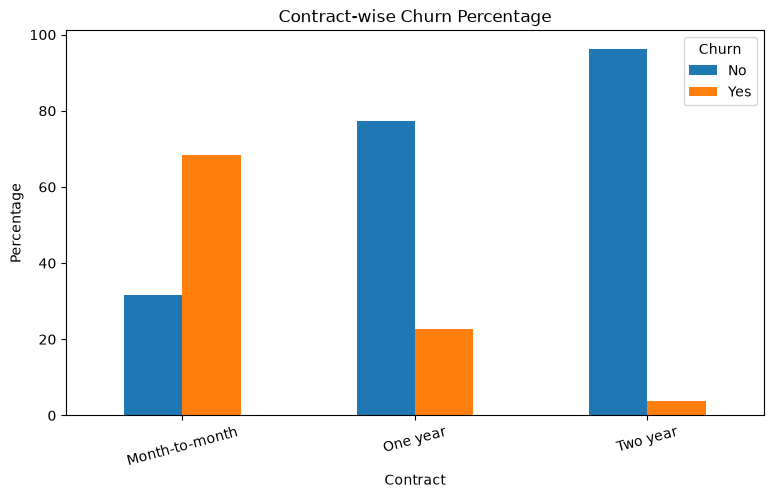

In [42]:
contract_churn.plot(
    kind="bar",
    figsize=(9,5)
)

plt.title("Contract-wise Churn Percentage")
plt.xlabel("Contract")
plt.ylabel("Percentage")

plt.xticks(rotation=15)
plt.legend(title="Churn")

plt.show()

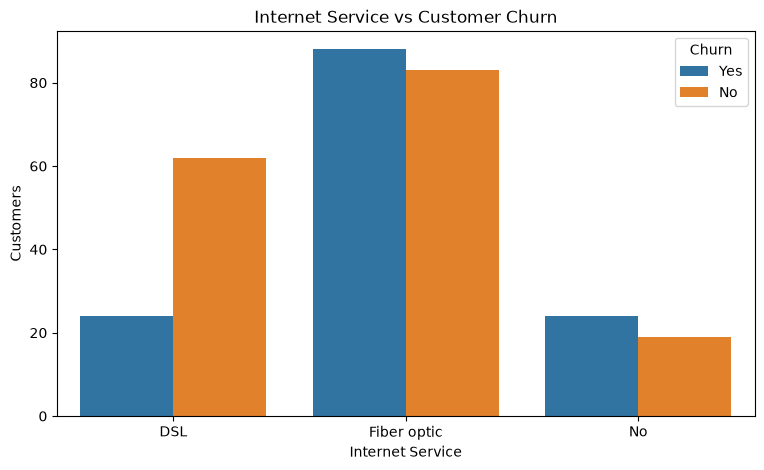

In [43]:
plt.figure(figsize=(9,5))

sns.countplot(
    x="InternetService",
    hue="Churn",
    data=data
)

plt.title("Internet Service vs Customer Churn")
plt.xlabel("Internet Service")
plt.ylabel("Customers")

plt.show()

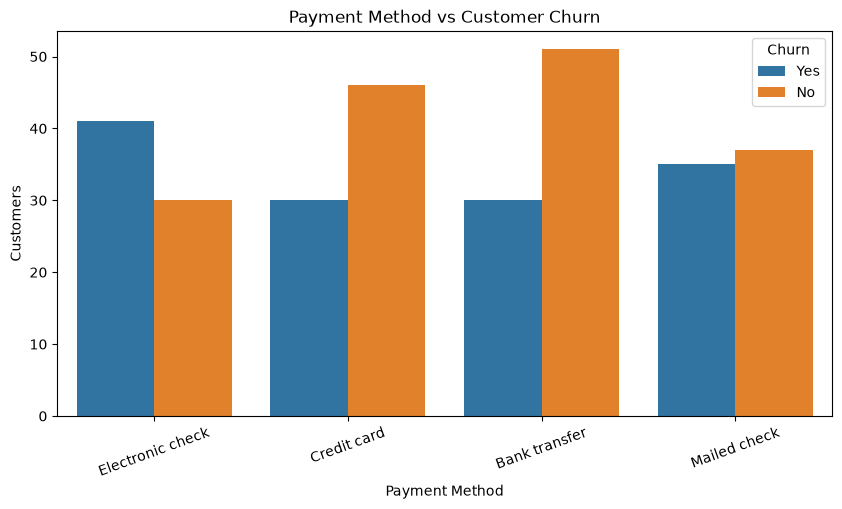

In [44]:
plt.figure(figsize=(10,5))

sns.countplot(
    x="PaymentMethod",
    hue="Churn",
    data=data
)

plt.title("Payment Method vs Customer Churn")
plt.xlabel("Payment Method")
plt.ylabel("Customers")

plt.xticks(rotation=20)

plt.show()

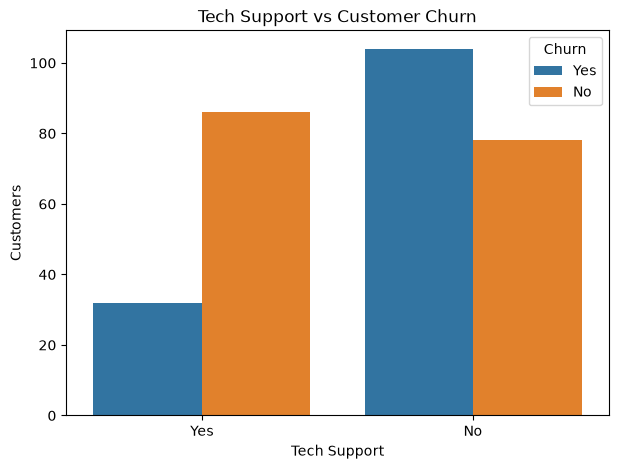

In [45]:
plt.figure(figsize=(7,5))

sns.countplot(
    x="TechSupport",
    hue="Churn",
    data=data
)

plt.title("Tech Support vs Customer Churn")
plt.xlabel("Tech Support")
plt.ylabel("Customers")

plt.show()

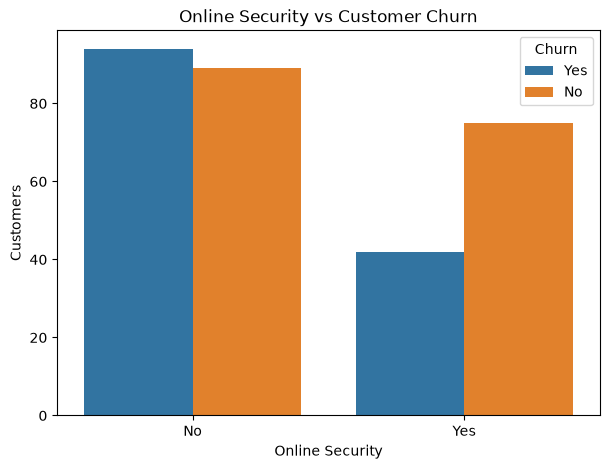

In [46]:
plt.figure(figsize=(7,5))

sns.countplot(
    x="OnlineSecurity",
    hue="Churn",
    data=data
)

plt.title("Online Security vs Customer Churn")
plt.xlabel("Online Security")
plt.ylabel("Customers")

plt.show()

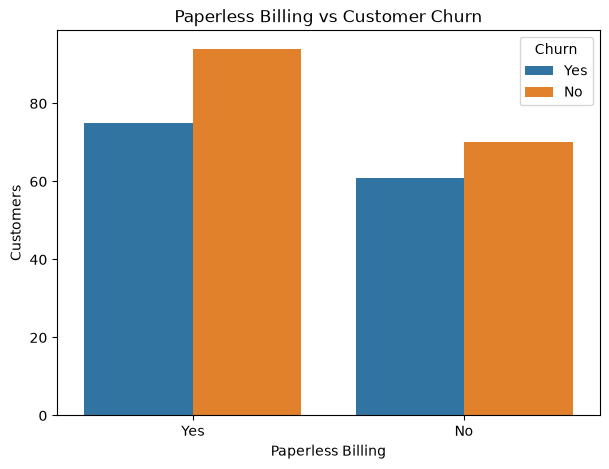

In [47]:
# Paperless Billing Churn
plt.figure(figsize=(7,5))

sns.countplot(
    x="PaperlessBilling",
    hue="Churn",
    data=data
)

plt.title("Paperless Billing vs Customer Churn")
plt.xlabel("Paperless Billing")
plt.ylabel("Customers")

plt.show()

In [50]:
# Churn Rate by Tenure
tenure_churn = pd.crosstab(
    data["Tenure"],
    data["Churn"],
    normalize="index"
) * 100

print(tenure_churn)

Churn          No         Yes
Tenure                       
0        0.000000  100.000000
1       50.000000   50.000000
2       25.000000   75.000000
3       33.333333   66.666667
4        0.000000  100.000000
...           ...         ...
68      33.333333   66.666667
69      70.000000   30.000000
70      50.000000   50.000000
71      60.000000   40.000000
72      33.333333   66.666667

[72 rows x 2 columns]


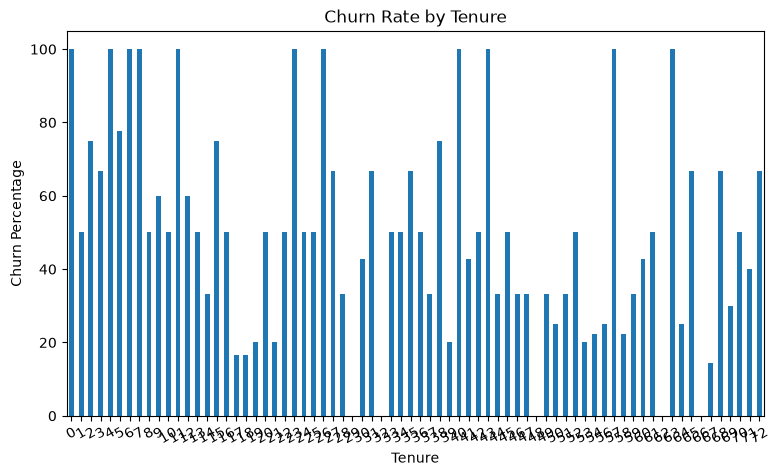

In [51]:
tenure_churn["Yes"].plot(
    kind="bar",
    figsize=(9,5)
)

plt.title("Churn Rate by Tenure")
plt.xlabel("Tenure")
plt.ylabel("Churn Percentage")

plt.xticks(rotation=30)
plt.show()

In [1]:
data.head()

NameError: name 'data' is not defined

In [55]:
# ML Peocessing

import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Load data
data = pd.read_csv("customer_churn_clean.csv")

# Separate X and y
X = data[["CustomerID","Gender","Age","Tenure","MonthlyCharges","Contract","InternetService","PaymentMethod","TechSupport","OnlineSecurity","PaperlessBilling"]]
y = data["Churn"]

# Remove CustomerID
X = X.drop("CustomerID", axis=1)

# Find columns
numerical_columns = X.select_dtypes(
    include=np.number
).columns

categorical_columns = X.select_dtypes(
    include="object"
).columns

# One-hot encoding
X_encoded = pd.get_dummies(
    X,
    columns=categorical_columns,
    drop_first=True
)

# Encode target
y = y.map({
    "No": 0,
    "Yes": 1
})

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X_encoded,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)

X_train: (240, 14)
X_test : (60, 14)
y_train: (240,)
y_test : (60,)


C:\Users\HP\AppData\Local\Temp\ipykernel_6992\207542864.py:24: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = X.select_dtypes(
